# 02 · Radar: read and explore

*What a weather radar actually measures and why nobody uses one radar on its own.*

A weather station measures the air at one point. A **weather radar** measures a whole region at once. It spins an antenna that sends out short pulses of microwaves and listens for the echo. Raindrops, snowflakes, hail and also birds, insects and the sea surface send some of that energy back. How strong the echo is and how long it took to return say what's out there and how far away.

The US network is called NEXRAD and has about 160 radars. Each one writes its raw output as **Level II** data: one file per **volume scan** which is a full set of 360° turns at several tilt angles every five or so minutes. I downloaded every volume from two California radars for five big storm days. KMUX sits on Mount Umunhum above the Bay Area and KVTX on Sulphur Mountain above Ventura.

There's also a second radar product. **MRMS** (Multi-Radar Multi-Sensor) is NOAA's national mosaic. It merges every radar onto one 1 km grid, cleans out echoes that aren't weather and turns the result into rainfall. I have its hourly rainfall for all of 2021–2024. Notebook 10 will compare it with station rain gauges.

This notebook reads both and looks for the things that make radar tricky. The radar sees things that aren't rain. Its beam climbs away from the ground as it goes out. And turning an echo into rain takes a formula that's only roughly right.

In [1]:
# Setup: identical in every notebook. Data lives in ../data, which git ignores.
import os
DATA_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "data"))
os.makedirs(DATA_DIR, exist_ok=True)
print("Data directory:", DATA_DIR)

Data directory: /Users/ashu/Workspace/weather-data-lab/data


In [2]:
import warnings; warnings.filterwarnings("ignore")
os.environ["PYART_QUIET"] = "1"   # skip Py-ART's welcome banner
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyart
from pathlib import Path
from wxlab import radar as rd

plt.rcParams["figure.dpi"] = 80
RAW = Path(DATA_DIR) / "raw"
KMUX_LAT, KMUX_LON, KMUX_ALT = 37.155, -121.898, 1081.0   # from the volume's own metadata

## Step 1 · One volume

Lets start in the middle of the October 2021 "bomb cyclone", a storm that set a one-day rainfall record in Sacramento. Here's one KMUX volume from 18:52 UTC and its list of **sweeps** (one 360° turn at one tilt).

In [3]:
f = [p for p in rd.level2_files(RAW, "KMUX", "2021-10-24") if p.name.startswith("KMUX20211024_1852")][0]
radar = rd.read_volume(f)
print(f"{f.name}: {f.stat().st_size / 1e6:.1f} MB, {radar.nsweeps} sweeps, {radar.nrays:,} rays, "
      f"{radar.ngates:,} gates of {radar.range['data'][1] - radar.range['data'][0]:.0f} m "
      f"out to {radar.range['data'][-1] / 1e3:.0f} km")
rd.sweep_table(radar)

KMUX20211024_185215_V06: 11.9 MB, 17 sweeps, 9,000 rays, 1,832 gates of 250 m out to 460 km


,elevation_deg,rays,nyquist_m_s,fields
sweep,,,,
0,0.00,720,8.8,"CFP, PhiDP, Z, ZDR, rhoHV"
1,0.00,720,27.7,"SW, V, Z"
2,0.48,720,8.8,"CFP, PhiDP, Z, ZDR, rhoHV"
3,0.48,720,27.7,"SW, V, Z"
4,0.88,720,8.8,"CFP, PhiDP, Z, ZDR, rhoHV"
5,0.88,720,27.7,"SW, V, Z"
6,1.32,720,9.5,"CFP, PhiDP, Z, ZDR, rhoHV"
7,1.32,720,27.7,"SW, V, Z"
8,1.80,360,27.7,"CFP, PhiDP, SW, V, Z, ZDR, rhoHV"


The geometry is polar. Each sweep is a set of **rays** (one per half or whole degree of azimuth) and each ray is cut into **range gates** 250 m long. So the data is a stack of azimuth × range grids, one per tilt and not a map.

Two details stand out in the table. First, the lowest tilts appear twice. This is a **split cut**. The first pass waits a long time between pulses so it can hear echoes from far away and it measures reflectivity and the dual-polarization fields. The second pass fires pulses quickly so it can measure wind speed which needs a high **Nyquist velocity** (the fastest speed the radar can measure before it wraps around). The two passes can't be the same pass because those two needs pull in opposite directions.

Second, KMUX's lowest tilt is 0.0° and not the usual 0.5°. KMUX sits 1 km up a mountain and has been allowed to scan lower since late 2018 so it sees more of the air near the ground ([NOAA ROC, 2019](https://www.roc.noaa.gov/public-documents/field-requirements-branch/tac/meetings/2019/TAC%202019%20Low%20Elevation%20Angle.pdf)). The next step shows why that matters.

## Step 2 · What the fields say

A modern radar sends pulses in two orientations at once, horizontal and vertical. That's **dual polarization** and it's what lets a radar tell rain from things that aren't rain. Three fields matter most here:

- **Reflectivity** (Z, in dBZ) is how much energy comes back. It grows very fast with drop size. Light rain is around 20 dBZ and heavy rain 45 or more.
- **Radial velocity** (V) is how fast the targets move toward or away from the radar (from the Doppler shift). Only motion along the beam shows up.
- **Correlation coefficient** (ρHV, "rho") compares the horizontal and vertical echoes pulse by pulse. Rain gives near-identical echoes so ρHV sits above about 0.97. Birds, insects, ground clutter and the sea surface tumble and vary so ρHV drops well below 0.9.

Lowest sweep: 13% of gates with an echo have ρHV below 0.8


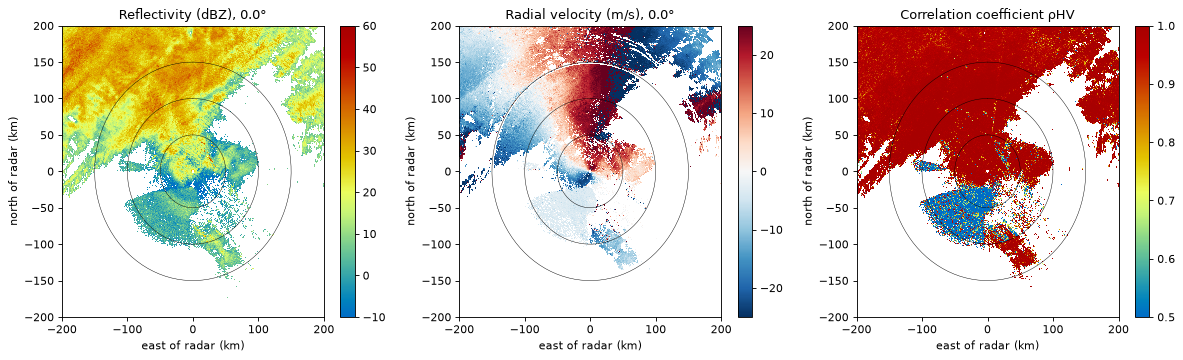

In [4]:
display = pyart.graph.RadarDisplay(radar)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
panels = [("reflectivity", 0, -10, 60, "HomeyerRainbow", "Reflectivity (dBZ), 0.0°"),
          ("velocity", 1, -25, 25, "RdBu_r", "Radial velocity (m/s), 0.0°"),
          ("cross_correlation_ratio", 0, 0.5, 1.0, "HomeyerRainbow", "Correlation coefficient ρHV")]
for ax, (field, sweep, vmin, vmax, cmap, title) in zip(axes, panels):
    display.plot_ppi(field, sweep, ax=ax, vmin=vmin, vmax=vmax, cmap=cmap, title=title,
                     colorbar_label="", axislabels=("east of radar (km)", "north of radar (km)"))
    display.set_limits((-200, 200), (-200, 200), ax=ax)
    display.plot_range_rings([50, 100, 150], ax=ax, lw=0.4)
plt.tight_layout()

sl = radar.get_slice(0)
z = radar.fields["reflectivity"]["data"][sl]
rho = radar.fields["cross_correlation_ratio"]["data"][sl]
both = ~np.ma.getmaskarray(z) & ~np.ma.getmaskarray(rho)
print(f"Lowest sweep: {(rho[both] < 0.8).mean():.0%} of gates with an echo have ρHV below 0.8")

The reflectivity panel shows the storm's band of rain across the north and a weaker patch to the south-west. The ρHV panel says that patch isn't rain at all. ρHV there is scattered between 0.5 and 0.8. It sits over Monterey Bay and the open ocean so it's most likely sea clutter which is the radar seeing waves when the beam is aimed this low. About one in eight gates with an echo in this sweep isn't weather.

A pipeline that turned reflectivity straight into rain would put a few millimetres an hour on the ocean. That's why every rain product starts by removing non-weather echoes and ρHV is the main tool for it. The velocity panel is the storm's wind seen along the beam. Blue is toward the radar and red is away and the white zero line runs across the wind's direction.

## Step 3 · The beam leaves the ground

A radar beam is straight but the Earth curves away beneath it. The air also bends the beam down a little and the standard way to handle that is to pretend the Earth is a third bigger (the **4/3 Earth model**). Here's how high the beam centre is at a few distances.

In [5]:
ranges = np.array([25, 50, 100, 150, 200]) * 1e3
pd.DataFrame({
    "KMUX at 0.0°": rd.beam_height(ranges, 0.0, KMUX_ALT),
    "KMUX at 0.5°": rd.beam_height(ranges, 0.5, KMUX_ALT),
}, index=pd.Index((ranges / 1e3).astype(int), name="range (km)")).round(-1).astype(int).rename_axis(columns="beam height above sea level (m)")

beam height above sea level (m),KMUX at 0.0°,KMUX at 0.5°
range (km),,
25,1120,1340
50,1230,1660
100,1670,2540
150,2410,3710
200,3440,5180


At 150 km KMUX's lowest beam is already 2.4 km up and the beam is also a couple of km wide by then. In a California winter storm the snow line is often only a couple of km up. So far from the radar the beam looks at the top of the rain or at melting snow and misses whatever happens below it. Rain that forms in the lowest kilometre can be almost invisible. Scanning at 0.0° instead of 0.5° lowers the beam by about 0.9 km at 100 km and 1.3 km at 150 km. That's the whole reason for it.

## Step 4 · From echo to rain

A radar doesn't measure rain. Reflectivity grows with roughly the sixth power of drop size while rain rate grows with roughly the 3.5th power. So the conversion is an empirical **Z–R relationship** of the form Z = a·R^b and a and b depend on the kind of rain. The WSR-88D's long-standing default is Z = 300·R^1.4 (Fulton et al. 1998, "The WSR-88D Rainfall Algorithm", *Weather and Forecasting* 13).

`rd.radar_rain_on_grid` turns each KMUX volume between 22:00 and 23:00 UTC into rain rates with that formula and drops gates with ρHV below 0.9. Then it adds up an hour of rain on the MRMS grid. I set it beside two MRMS products for the same hour. *Radar only* is MRMS's own radar estimate. *Multi-sensor* also blends in rain gauges which makes it better but not independent of gauges.

,KMUX alone,MRMS radar only,MRMS multi-sensor
km from radar,,,
"(0, 50]",0.59,0.92,1.81
"(50, 100]",1.16,1.25,2.42
"(100, 150]",2.71,3.45,4.82


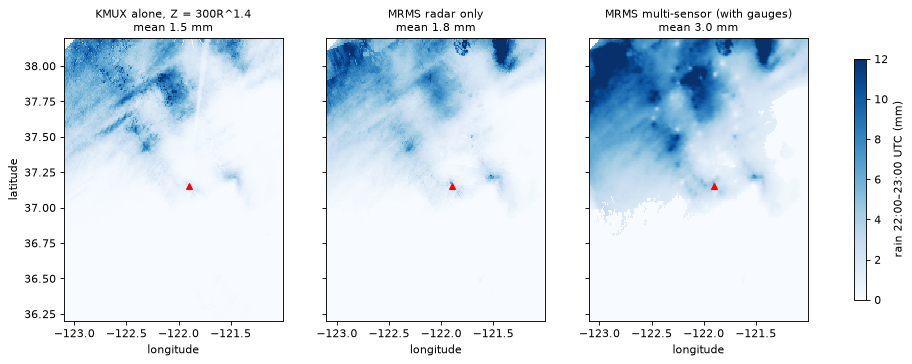

In [6]:
box = (36.2, 38.2, 236.9, 239.0)   # lat min, lat max, lon min, lon max (degrees east, as MRMS uses)
end = pd.Timestamp("2021-10-24 23:00", tz="UTC")
radar_only = rd.read_mrms(rd.mrms_path(RAW, "RadarOnly_QPE_01H_00.00", end), box=box)
multi = rd.read_mrms(rd.mrms_path(RAW, "MultiSensor_QPE_01H_Pass2_00.00", end), box=box)

files = [p for p in rd.level2_files(RAW, "KMUX", "2021-10-24")
         if end - pd.Timedelta("70min") <= rd.volume_time(p) <= end + pd.Timedelta("10min")]
kmux = rd.radar_rain_on_grid(files, end - pd.Timedelta("1h"), end,
                             radar_only.latitude.values, radar_only.longitude.values)

lat, lon = np.meshgrid(radar_only.latitude.values, radar_only.longitude.values, indexing="ij")
dist = np.hypot((lat - KMUX_LAT) * 111, (lon - 360 - KMUX_LON) * 111 * np.cos(np.deg2rad(KMUX_LAT)))
near = dist < 150

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, (title, field) in zip(axes, [("KMUX alone, Z = 300R^1.4", np.where(near, kmux, np.nan)),
                                     ("MRMS radar only", radar_only.where(near).values),
                                     ("MRMS multi-sensor (with gauges)", multi.where(near).values)]):
    m = ax.pcolormesh(radar_only.longitude - 360, radar_only.latitude, field, vmin=0, vmax=12, cmap="Blues")
    ax.plot(KMUX_LON, KMUX_LAT, "r^")
    ax.set_title(f"{title}\nmean {np.nanmean(field[near]):.1f} mm", fontsize=10)
    ax.set_xlabel("longitude")
axes[0].set_ylabel("latitude")
fig.colorbar(m, ax=axes, label="rain 22:00–23:00 UTC (mm)", shrink=0.85)

rings = pd.cut(pd.Series(dist[near]), [0, 50, 100, 150])
pd.DataFrame({"KMUX alone": kmux[near], "MRMS radar only": radar_only.values[near],
              "MRMS multi-sensor": multi.values[near]}).groupby(rings.values, observed=True).mean().round(2).rename_axis("km from radar")

The three maps agree on where the rain is. They disagree on how much. My one-radar estimate and MRMS's radar-only estimate are close to each other. Both are well below the multi-sensor value at every distance and over the whole area they come to about half of it. The gauges on the ground caught about twice what the radars saw.

That's a known weakness in this kind of storm. An atmospheric river is warm and much of its rain grows in the lowest kilometre from many small drops. Small drops give little reflectivity for the rain they carry so the default Z–R undercounts. And as step 3 showed the beam far out is above where that rain forms. Over the whole day the pattern holds. In every rainy hour MRMS's radar-only rain near the Bay Area is between about 40% and 75% of the multi-sensor rain. This is exactly the kind of disagreement between sources that notebook 10 will measure against station gauges.

## Step 5 · When the radar goes quiet

Coverage is the first QA question for any source. Here's how many volumes I have per hour for each radar and storm day.

radar,KMUX,KVTX
day,,
2021-10-24,240,148
2021-12-14,262,280
2023-01-09,78,223
2023-08-21,220,286
2024-02-05,249,215


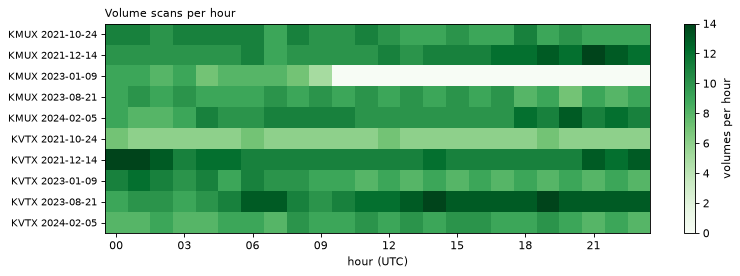

In [7]:
counts = rd.volume_counts(RAW)
grid = counts.pivot_table(index=["radar", "day"], columns="hour", values="volumes")
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(grid.values, cmap="Greens", aspect="auto", vmin=0, vmax=14)
ax.set_yticks(range(len(grid)), [f"{r} {d}" for r, d in grid.index], fontsize=9)
ax.set_xticks(range(0, 24, 3), [f"{h:02d}" for h in range(0, 24, 3)])
ax.set_xlabel("hour (UTC)")
fig.colorbar(im, ax=ax, label="volumes per hour")
ax.set_title("Volume scans per hour", loc="left", fontsize=10)
counts.groupby(["radar", "day"]).volumes.sum().unstack(0)

Most rows are steady at 8–12 volumes an hour. During rain the radar switches to a faster **scan strategy**. KVTX on 24 October 2021 is lighter because that storm hit northern California and KVTX spent the day in a slower clear-air mode.

KMUX on 9 January 2023 is the exception. Its volumes stop at 09:34 UTC and don't come back until 03:58 UTC the next day. That's an 18-hour hole in the middle of one of the worst storms of that winter and the public archive has nothing for those hours either. I didn't find a public notice of why.

The mosaic doesn't show the hole. MRMS still has rain over the Bay Area every hour that day because neighbouring radars such as KDAX near Sacramento cover it from farther away which also means from higher up. Whether that made the mosaic drier is hard to tell from one storm. Its radar-only rain was 37% of the gauge-blended rain at 11 UTC and 80% at 17 UTC (both inside the gap). A product built from many sources can look complete while one of its inputs is missing so the gap has to be tracked in the inputs. That's the same lesson as notebook 04's storm gaps, one level up.

## Step 6 · Formats and size

A Level II file is the radar's own message stream: blocks of bzip2-compressed binary messages (one per ray). A stormy day is about 250 volumes and 2.6 GB per radar so 160 radars make a few hundred GB a day. The stations make a few MB.

MRMS is a regular 3500 × 7000 grid stored as gzipped GRIB2 (about 0.5 MB an hour for this product). `rd.read_mrms` handles its two traps. It uses NOAA's own GRIB2 tables so generic readers call the variable "unknown". And −3 means "no coverage" and must not be read as rain.

Polar volumes don't fit formats built for grids. The newer approach stores each radar as a tree of sweeps in Zarr (the FM-301 / CfRadial2 standard) which xradar reads directly. Notebook 11 picks that thread up.

## What I learned

- **The radar saw about half the rain.** Two independent radar estimates agreed with each other and both got half to three quarters of the gauge-blended amount. Far from the radar the beam is above rain that forms near the ground and no formula can count rain it never saw.
- **A radar's lowest beam isn't low.** 150 km out KMUX looks at air 2.4 km up even when it scans flat.
- **Not every echo is rain.** One in eight echoes on the lowest sweep was sea clutter during a major storm. The correlation coefficient gives it away because rain returns nearly identical horizontal and vertical echoes.
- **Scanning is a trade-off.** Seeing far needs a long wait between pulses and measuring fast wind needs short ones. KMUX scans each low tilt twice to get both.
- **A gap can hide inside a mosaic.** KMUX went silent for 18 hours in a flood-producing storm and the national product still looked complete.

**Still open:** why are those 18 hours missing? Was the radar down or did its data never reach the archive?